# Inventory Obsolescence Risk Classification Using Decision Tree

The objective of this project is to classify inventory items into **Low, Medium and High Obsolescence Risk** using a **Decision Tree Classifier**.

The target variable `Obsolescence_Risk` is a **derived target variable** created from inventory business logic using the actual dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
df = pd.read_csv("enhanced_smart_waste_dataset_v1.csv")

df.head()

,ItemName,Brand,Category,StockQty,ArrivalDate,ExpiryDate,DaysUntilExpiry,DailySaleAvg,SpoilageChance,SuggestedAction,StoreLocation,IsSpoiled,OnPromotion,TemperatureSensitive,StoreID,Zone,TemperatureSupport,DistanceToNearestStore,AvgDailySaleInNearbyStores
0,Bingo Mad Angles,ITC,Snacks,92,20-06-2025,28-06-2025,0.5,12.1,1.0,donate,Chennai,False,No,False,Chennai_0,NaN,NaN,6.1,13.178196
1,Multigrain Cookies,Sunfeast,Bakery,224,18-06-2025,29-06-2025,1.0,9.0,1.0,donate,Kanpur,True,No,False,Kanpur_0,NaN,NaN,5.0,8.981118
2,Nestlé Yogurt 150g,Nestlé,Dairy,201,23-06-2025,26-06-2025,0.5,20.1,1.0,donate,Mumbai,False,Yes,True,Mumbai_0,West,False,10.3,17.169273
3,Tomato 1kg,Local Farmer,Produce,204,18-06-2025,21-06-2025,0.5,9.7,1.0,donate,Kanpur,False,Yes,True,Kanpur_1,NaN,NaN,8.8,11.075997
4,Banana 6pcs,Local Farmer,Produce,154,14-06-2025,21-06-2025,0.5,5.6,1.0,donate,Mumbai,True,Yes,True,Mumbai_1,West,False,10.4,4.641460


In [3]:
df.shape

(1000, 19)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ItemName                    1000 non-null   object 
 1   Brand                       1000 non-null   object 
 2   Category                    1000 non-null   object 
 3   StockQty                    1000 non-null   int64  
 4   ArrivalDate                 1000 non-null   object 
 5   ExpiryDate                  1000 non-null   object 
 6   DaysUntilExpiry             1000 non-null   float64
 7   DailySaleAvg                1000 non-null   float64
 8   SpoilageChance              1000 non-null   float64
 9   SuggestedAction             1000 non-null   object 
 10  StoreLocation               1000 non-null   object 
 11  IsSpoiled                   1000 non-null   bool   
 12  OnPromotion                 1000 non-null   object 
 13  TemperatureSensitive        1000 n

In [5]:
df.describe()

,StockQty,DaysUntilExpiry,DailySaleAvg,SpoilageChance,DistanceToNearestStore,AvgDailySaleInNearbyStores
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,156.931000,2.074000,12.693300,0.816530,8.276600,12.671447
std,90.173452,2.582381,6.765119,0.289947,3.797469,6.880845
min,11.000000,0.500000,0.600000,0.080000,2.000000,0.490610
25%,60.000000,0.500000,8.900000,0.580000,5.000000,7.988302
50%,162.000000,0.500000,12.700000,1.000000,8.100000,12.215790
75%,232.000000,3.000000,17.100000,1.000000,11.600000,17.623205
max,295.000000,10.000000,24.600000,1.000000,15.000000,28.818681


In [6]:
df.isnull().sum()

ItemName                        0
Brand                           0
Category                        0
StockQty                        0
ArrivalDate                     0
ExpiryDate                      0
DaysUntilExpiry                 0
DailySaleAvg                    0
SpoilageChance                  0
SuggestedAction                 0
StoreLocation                   0
IsSpoiled                       0
OnPromotion                     0
TemperatureSensitive            0
StoreID                         0
Zone                          656
TemperatureSupport            656
DistanceToNearestStore          0
AvgDailySaleInNearbyStores      0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.nunique()

ItemName                        15
Brand                           10
Category                         5
StockQty                        48
ArrivalDate                     15
ExpiryDate                      24
DaysUntilExpiry                 11
DailySaleAvg                    44
SpoilageChance                  18
SuggestedAction                  4
StoreLocation                    5
IsSpoiled                        2
OnPromotion                      2
TemperatureSensitive             2
StoreID                       1000
Zone                             2
TemperatureSupport               2
DistanceToNearestStore         131
AvgDailySaleInNearbyStores    1000
dtype: int64

In [9]:
# Check missing values
df.isnull().sum()

ItemName                        0
Brand                           0
Category                        0
StockQty                        0
ArrivalDate                     0
ExpiryDate                      0
DaysUntilExpiry                 0
DailySaleAvg                    0
SpoilageChance                  0
SuggestedAction                 0
StoreLocation                   0
IsSpoiled                       0
OnPromotion                     0
TemperatureSensitive            0
StoreID                         0
Zone                          656
TemperatureSupport            656
DistanceToNearestStore          0
AvgDailySaleInNearbyStores      0
dtype: int64

In [10]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [11]:
# Check categorical values
print("Category values:")
print(df["Category"].unique())

print("\nStore Location values:")
print(df["StoreLocation"].unique())

print("\nOn Promotion values:")
print(df["OnPromotion"].unique())

Category values:
['Snacks' 'Bakery' 'Dairy' 'Produce' 'Meat']

Store Location values:
['Chennai' 'Kanpur' 'Mumbai' 'Delhi' 'Bangalore']

On Promotion values:
['No' 'Yes']


In [12]:
# Convert date columns to datetime only for checking the date format
df["ArrivalDate"] = pd.to_datetime(df["ArrivalDate"], dayfirst=True)
df["ExpiryDate"] = pd.to_datetime(df["ExpiryDate"], dayfirst=True)

df[["ArrivalDate", "ExpiryDate"]].head()

,ArrivalDate,ExpiryDate
0,2025-06-20,2025-06-28
1,2025-06-18,2025-06-29
2,2025-06-23,2025-06-26
3,2025-06-18,2025-06-21
4,2025-06-14,2025-06-21


Before modelling, each original column was reviewed for usefulness, redundancy and leakage.

| Column | Decision | Reason |
|---|---|---|
| ItemName | Delete | Product-level detail with limited generalisation; Category and Brand provide simpler information |
| Brand | Keep | Useful product/business information |
| Category | Keep | Useful for comparing inventory risk across product groups |
| StockQty | Delete from model | Used to derive the risk target |
| ArrivalDate | Delete | Date detail is not needed because useful expiry information is already available |
| ExpiryDate | Delete | `DaysUntilExpiry` gives the relevant remaining shelf-life information |
| DaysUntilExpiry | Delete from model | Used to derive the risk target |
| DailySaleAvg | Delete from model | Used to derive the risk target |
| SpoilageChance | Delete | Leakage-prone because it directly represents spoilage likelihood |
| SuggestedAction | Delete | Likely based on the inventory condition and can reveal the outcome |
| StoreLocation | Keep | Useful store-level business information |
| IsSpoiled | Delete | Direct outcome information and therefore leakage-prone |
| OnPromotion | Keep | Promotion may influence inventory movement |
| TemperatureSensitive | Keep | Useful product characteristic |
| StoreID | Delete | Unique identifier; not a meaningful general predictor |
| Zone | Delete | 656 missing values and largely redundant with StoreLocation |
| TemperatureSupport | Delete | 656 missing values and largely redundant with StoreLocation |
| DistanceToNearestStore | Keep | May affect the possibility of moving inventory between stores |
| AvgDailySaleInNearbyStores | Delete from model | Used in the target-risk reasoning as a demand indicator |

In [13]:
# Check for zero values before calculating Stock Coverage Days
print("Zero DailySaleAvg values:", (df["DailySaleAvg"] == 0).sum())

Zero DailySaleAvg values: 0


In [14]:
# Calculate how many days the current stock can last
df["Stock_Coverage_Days"] = np.where(
    df["DailySaleAvg"] > 0,
    df["StockQty"] / df["DailySaleAvg"],
    np.nan
)

df[["StockQty", "DailySaleAvg", "Stock_Coverage_Days"]].head()

,StockQty,DailySaleAvg,Stock_Coverage_Days
0,92,12.1,7.603306
1,224,9.0,24.888889
2,201,20.1,10.000000
3,204,9.7,21.030928
4,154,5.6,27.500000


In [15]:
df["Stock_Coverage_Days"].describe()

count    1000.000000
mean       26.344930
std        44.984220
min         0.780142
25%         4.563107
50%        11.991870
75%        22.432870
max       246.666667
Name: Stock_Coverage_Days, dtype: float64

In [16]:
# Create a simple business indicator:
# how many stock-coverage days exist for every remaining expiry day

df["Coverage_to_Expiry_Ratio"] = (
    df["Stock_Coverage_Days"] / df["DaysUntilExpiry"]
)

df["Coverage_to_Expiry_Ratio"].describe()

count    1000.000000
mean       41.619797
std        91.196035
min         0.401786
25%         2.884615
50%        10.267857
75%        33.142857
max       493.333333
Name: Coverage_to_Expiry_Ratio, dtype: float64

In [17]:
# Use the actual dataset distribution to create relative risk bands
low_threshold = df["Coverage_to_Expiry_Ratio"].quantile(0.25)
high_threshold = df["Coverage_to_Expiry_Ratio"].quantile(0.75)

print("Low-risk threshold:", round(low_threshold, 2))
print("High-risk threshold:", round(high_threshold, 2))

Low-risk threshold: 2.88
High-risk threshold: 33.14


In [18]:
def create_risk(ratio):
    if ratio <= low_threshold:
        return "Low"
    elif ratio <= high_threshold:
        return "Medium"
    else:
        return "High"

df["Obsolescence_Risk"] = df["Coverage_to_Expiry_Ratio"].apply(create_risk)

df[["DaysUntilExpiry", "Stock_Coverage_Days",
    "Coverage_to_Expiry_Ratio", "Obsolescence_Risk"]].head()

,DaysUntilExpiry,Stock_Coverage_Days,Coverage_to_Expiry_Ratio,Obsolescence_Risk
0,0.5,7.603306,15.206612,Medium
1,1.0,24.888889,24.888889,Medium
2,0.5,10.000000,20.000000,Medium
3,0.5,21.030928,42.061856,High
4,0.5,27.500000,55.000000,High


In [19]:
df["Obsolescence_Risk"].value_counts()

Obsolescence_Risk
Medium    514
Low       252
High      234
Name: count, dtype: int64

In [20]:
risk_percentage = df["Obsolescence_Risk"].value_counts(normalize=True) * 100
risk_percentage.round(2)

Obsolescence_Risk
Medium    51.4
Low       25.2
High      23.4
Name: proportion, dtype: float64

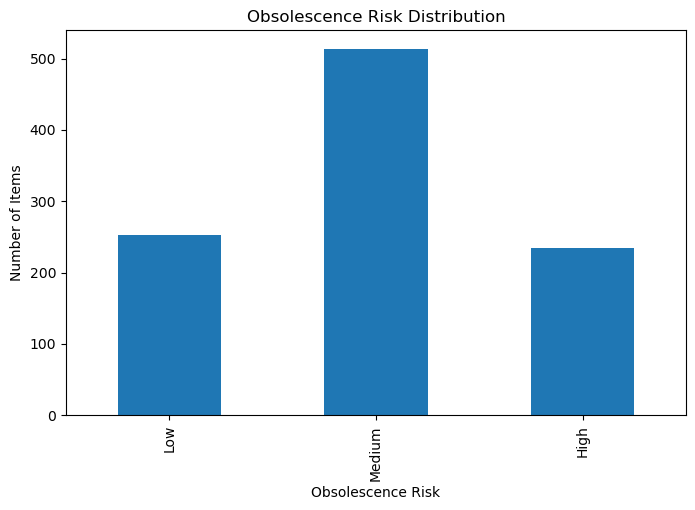

In [21]:
plt.figure(figsize=(8, 5))

df["Obsolescence_Risk"].value_counts().reindex(["Low", "Medium", "High"]).plot(kind="bar")

plt.title("Obsolescence Risk Distribution")
plt.xlabel("Obsolescence Risk")
plt.ylabel("Number of Items")

plt.show()

### Observation

The actual target distribution is:

- **Low:** 252 items (25.2%)
- **Medium:** 514 items (51.4%)
- **High:** 234 items (23.4%)

##  Exploratory Data Analysis

### 1. Stock Quantity by Obsolescence Risk

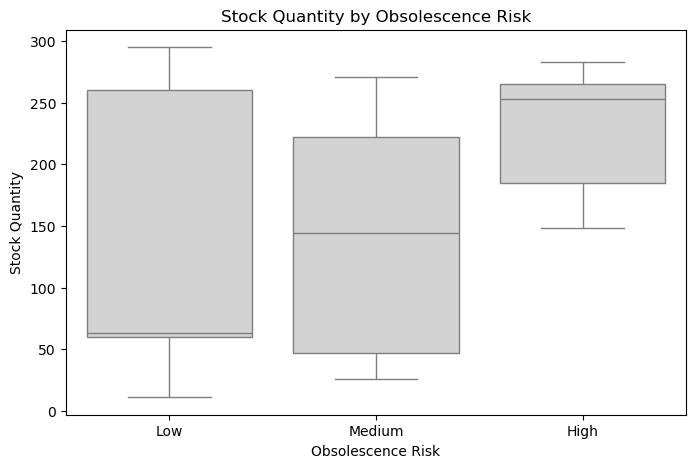

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Obsolescence_Risk", y="StockQty", order=["Low", "Medium", "High"], color="lightgray")

plt.title("Stock Quantity by Obsolescence Risk")
plt.xlabel("Obsolescence Risk")
plt.ylabel("Stock Quantity")

plt.show()

### Observation

The actual group means show that High-risk items have the highest average stock quantity:

- Low: **125.24**
- Medium: **141.61**
- High: **224.72**

This supports the business idea that larger stock levels can increase obsolescence pressure.

### 2. Days Until Expiry by Obsolescence Risk

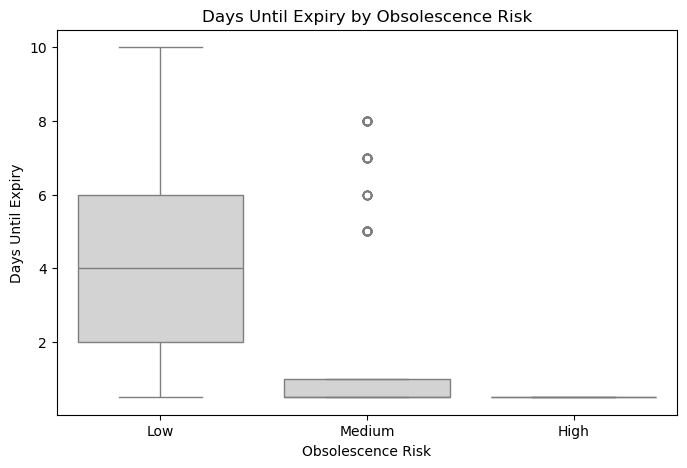

In [23]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Obsolescence_Risk", y="DaysUntilExpiry", order=["Low", "Medium", "High"], color="lightgray")

plt.title("Days Until Expiry by Obsolescence Risk")
plt.xlabel("Obsolescence Risk")
plt.ylabel("Days Until Expiry")

plt.show()

### Observation

The average remaining shelf life is:

- Low: **4.42 days**
- Medium: **1.64 days**
- High: **0.50 days**

High-risk items therefore have much less time remaining before expiry in this dataset.

### 3. Daily Sales Average by Obsolescence Risk

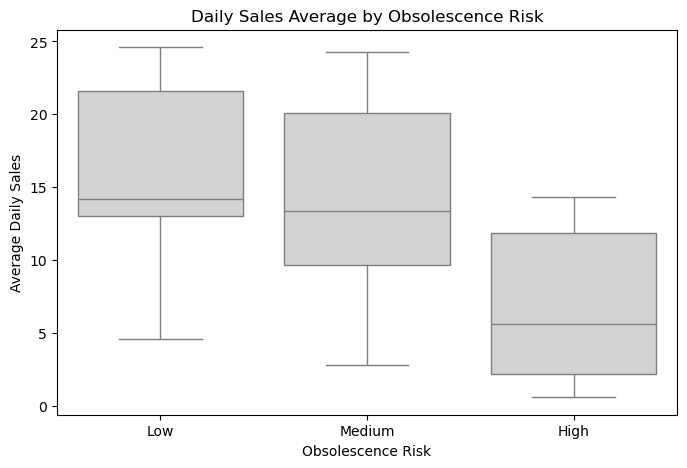

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Obsolescence_Risk", y="DailySaleAvg", order=["Low", "Medium", "High"], color="lightgray")

plt.title("Daily Sales Average by Obsolescence Risk")
plt.xlabel("Obsolescence Risk")
plt.ylabel("Average Daily Sales")

plt.show()

### Observation

Average daily sales are:

- Low: **15.98**
- Medium: **13.80**
- High: **6.72**

High-risk items have considerably lower average daily sales in the actual dataset.

### 4. Stock Coverage Days by Obsolescence Risk

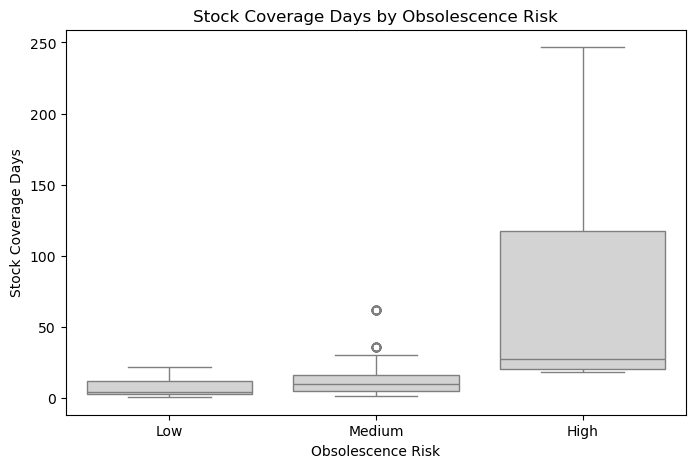

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Obsolescence_Risk", y="Stock_Coverage_Days", order=["Low", "Medium", "High"], color="lightgray")

plt.title("Stock Coverage Days by Obsolescence Risk")
plt.xlabel("Obsolescence Risk")
plt.ylabel("Stock Coverage Days")

plt.show()

### Observation

Average stock coverage is:

- Low: **7.71 days**
- Medium: **14.49 days**
- High: **72.46 days**

The large difference shows why stock coverage is useful for understanding inventory pressure. It is used for target creation but excluded from model inputs to avoid leakage.

### 5. Category vs Obsolescence Risk

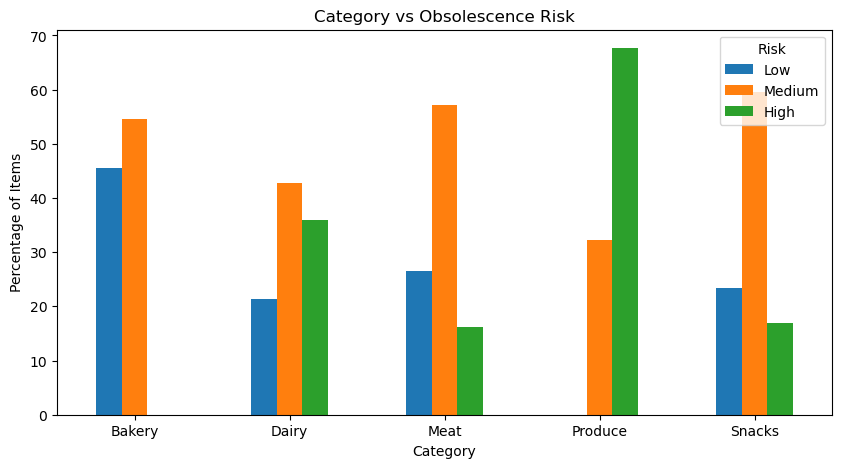

In [26]:
category_risk = pd.crosstab(
    df["Category"],
    df["Obsolescence_Risk"],
    normalize="index"
) * 100

category_risk = category_risk[["Low", "Medium", "High"]]

category_risk.round(2).plot(kind="bar", figsize=(10, 5))

plt.title("Category vs Obsolescence Risk")
plt.xlabel("Category")
plt.ylabel("Percentage of Items")

plt.xticks(rotation=0)
plt.legend(title="Risk")

plt.show()

### Observation

The actual category-wise distribution shows clear differences.

- **Produce** has the highest High-risk share at **67.7%**.
- **Bakery** has the highest Low-risk share at **45.5%**.
- **Snacks** and **Meat** are more concentrated in the Medium-risk class.

These are dataset-specific observations, not general claims about all retailers.

### 6. Store Location vs Obsolescence Risk

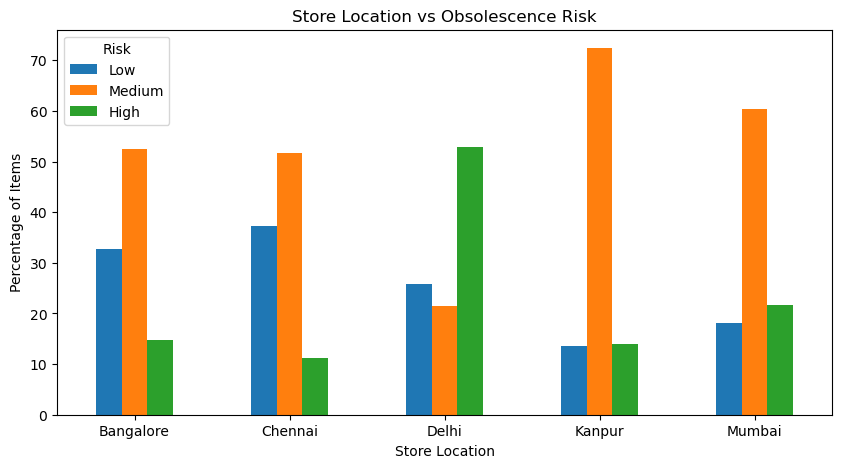

In [27]:
store_risk = pd.crosstab(
    df["StoreLocation"],
    df["Obsolescence_Risk"],
    normalize="index"
) * 100

store_risk = store_risk[["Low", "Medium", "High"]]

store_risk.round(2).plot(kind="bar", figsize=(10, 5))

plt.title("Store Location vs Obsolescence Risk")
plt.xlabel("Store Location")
plt.ylabel("Percentage of Items")

plt.xticks(rotation=0)
plt.legend(title="Risk")

plt.show()

### Observation

Delhi has the highest High-risk share at **52.8%**, while Chennai has the highest Low-risk share at **37.2%**.

Kanpur has the largest Medium-risk share at **72.4%**.

This suggests that location-related information may help the model distinguish risk levels.

### 7. On Promotion vs Obsolescence Risk

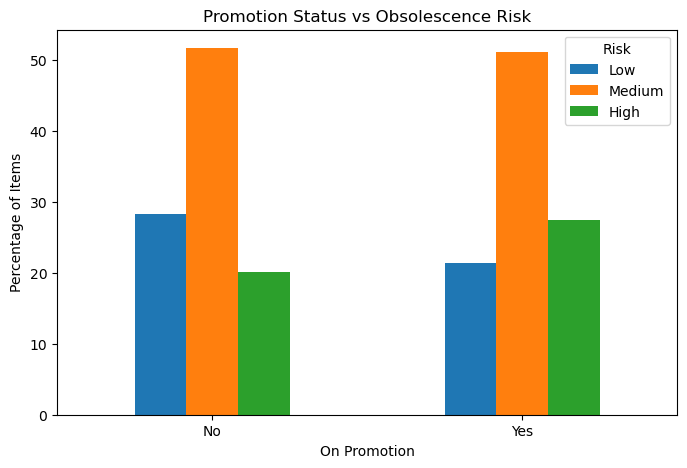

In [28]:
promotion_risk = pd.crosstab(
    df["OnPromotion"],
    df["Obsolescence_Risk"],
    normalize="index"
) * 100

promotion_risk = promotion_risk[["Low", "Medium", "High"]]

promotion_risk.round(2).plot(kind="bar", figsize=(8, 5))

plt.title("Promotion Status vs Obsolescence Risk")
plt.xlabel("On Promotion")
plt.ylabel("Percentage of Items")

plt.xticks(rotation=0)
plt.legend(title="Risk")

plt.show()

### Observation

High-risk items represent **27.5%** of promoted items compared with **20.1%** of non-promoted items in this dataset.

Therefore, promotion status shows an association with the derived risk classes, but this analysis alone does not prove that promotion causes higher risk.

### 8. Temperature Sensitive vs Obsolescence Risk

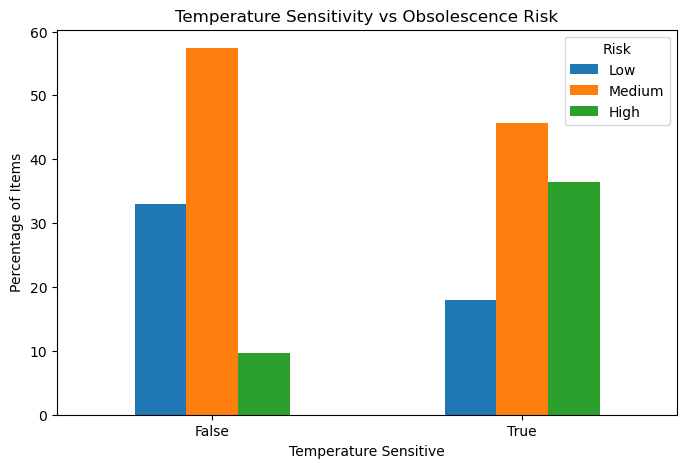

In [29]:
temperature_risk = pd.crosstab(
    df["TemperatureSensitive"],
    df["Obsolescence_Risk"],
    normalize="index"
) * 100

temperature_risk = temperature_risk[["Low", "Medium", "High"]]

temperature_risk.round(2).plot(kind="bar", figsize=(8, 5))

plt.title("Temperature Sensitivity vs Obsolescence Risk")
plt.xlabel("Temperature Sensitive")
plt.ylabel("Percentage of Items")

plt.xticks(rotation=0)
plt.legend(title="Risk")

plt.show()

### Observation

High-risk items make up **36.4%** of temperature-sensitive items compared with **9.7%** of non-temperature-sensitive items.

This is one of the clearer differences in the EDA.

### 9. Distance to Nearest Store vs Obsolescence Risk

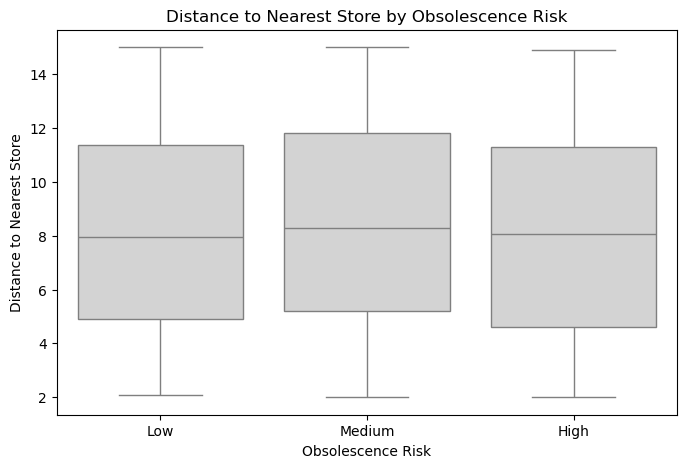

In [30]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Obsolescence_Risk", y="DistanceToNearestStore", order=["Low", "Medium", "High"], color="lightgray")

plt.title("Distance to Nearest Store by Obsolescence Risk")
plt.xlabel("Obsolescence Risk")
plt.ylabel("Distance to Nearest Store")

plt.show()

### Observation

The average distance is quite similar across the three groups:

- Low: **8.12**
- Medium: **8.48**
- High: **8.01**

So the EDA does not show a strong difference in average distance between risk groups.

### 10. Nearby Store Demand vs Obsolescence Risk

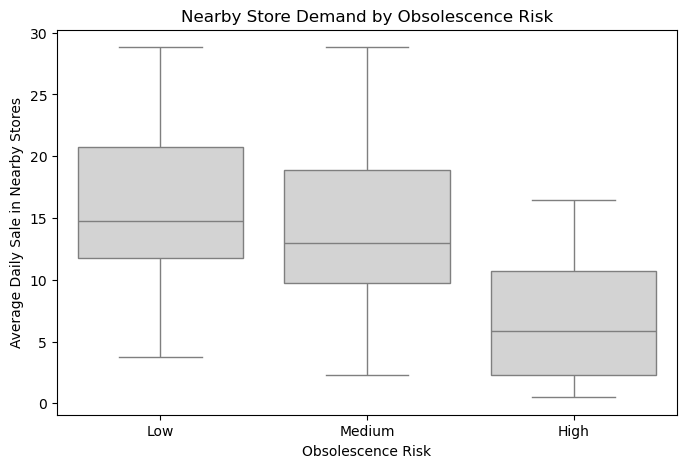

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Obsolescence_Risk", y="AvgDailySaleInNearbyStores", order=["Low", "Medium", "High"], color="lightgray")

plt.title("Nearby Store Demand by Obsolescence Risk")
plt.xlabel("Obsolescence Risk")
plt.ylabel("Average Daily Sale in Nearby Stores")

plt.show()

### Observation

Average nearby-store demand is:

- Low: **15.76**
- Medium: **13.83**
- High: **6.80**

High-risk items are associated with much lower nearby-store demand in this dataset. This variable is used in the target logic and therefore is excluded from the final model.

##  Encoding

In [32]:
# Make a copy of the columns that will be used in the model
model_df = df[
    [
        "Brand",
        "Category",
        "StoreLocation",
        "OnPromotion",
        "TemperatureSensitive",
        "DistanceToNearestStore",
        "Obsolescence_Risk"
    ]
].copy()

model_df.head()

,Brand,Category,StoreLocation,OnPromotion,TemperatureSensitive,DistanceToNearestStore,Obsolescence_Risk
0,ITC,Snacks,Chennai,No,False,6.1,Medium
1,Sunfeast,Bakery,Kanpur,No,False,5.0,Medium
2,Nestlé,Dairy,Mumbai,Yes,True,10.3,Medium
3,Local Farmer,Produce,Kanpur,Yes,True,8.8,High
4,Local Farmer,Produce,Mumbai,Yes,True,10.4,High


In [33]:
# Label Encoding for categorical columns
label_encoders = {}

categorical_columns = [
    "Brand",
    "Category",
    "StoreLocation",
    "OnPromotion"
]

for column in categorical_columns:
    le = LabelEncoder()
    model_df[column] = le.fit_transform(model_df[column])
    label_encoders[column] = le

# Convert Boolean column to 0 and 1
model_df["TemperatureSensitive"] = model_df["TemperatureSensitive"].astype(int)

model_df.head()

,Brand,Category,StoreLocation,OnPromotion,TemperatureSensitive,DistanceToNearestStore,Obsolescence_Risk
0,4,4,1,0,0,6.1,Medium
1,9,0,3,0,0,5.0,Medium
2,7,1,4,1,1,10.3,Medium
3,5,3,3,1,1,8.8,High
4,5,3,4,1,1,10.4,High


### Explanation

Only the categorical columns that remain in the final model are encoded.

Label Encoding changes categories into numbers so that the Decision Tree can work with them.



## Feature and Target Separation

In [34]:
X = model_df.drop("Obsolescence_Risk", axis=1)
y = model_df["Obsolescence_Risk"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Features:
['Brand', 'Category', 'StoreLocation', 'OnPromotion', 'TemperatureSensitive', 'DistanceToNearestStore']

Target:
Obsolescence_Risk

Feature shape: (1000, 6)
Target shape: (1000,)


##  Train-Test Split

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 6)
Testing data: (200, 6)


### Explanation

The data is divided into:

- **80% training data**
- **20% testing data**

`stratify=y` keeps the Low, Medium and High classes represented in a similar proportion in both sets.


##  Basic Decision Tree Model

In [36]:
decision_tree = DecisionTreeClassifier(random_state=42)

decision_tree.fit(X_train, y_train)

print("Basic Decision Tree model trained successfully.")

Basic Decision Tree model trained successfully.


### Explanation

This is the first simple Decision Tree model.

No tuning is performed yet. We first want to see how the basic model performs.



##  Model Prediction

In [37]:
y_pred = decision_tree.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results.head(10)

,Actual,Predicted
0,Medium,Medium
1,Low,High
2,Medium,Medium
3,High,Medium
4,Medium,Medium
5,Medium,Medium
6,Medium,Medium
7,Low,Low
8,Low,Low
9,High,High


### Explanation

The trained Decision Tree predicts the risk class for the unseen test data.

The predictions are compared with the actual Low, Medium and High labels.

##  Model Evaluation

In [38]:
basic_accuracy = accuracy_score(y_test, y_pred)

print("Basic Decision Tree Accuracy:", round(basic_accuracy, 4))

Basic Decision Tree Accuracy: 0.895


In [39]:
print("Classification Report - Basic Decision Tree")
print(classification_report(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"]
))

Classification Report - Basic Decision Tree
              precision    recall  f1-score   support

         Low       0.90      0.88      0.89        50
      Medium       0.90      0.92      0.91       103
        High       0.87      0.85      0.86        47

    accuracy                           0.90       200
   macro avg       0.89      0.88      0.89       200
weighted avg       0.89      0.90      0.89       200



### Actual Basic Model Result

The basic Decision Tree achieved approximately **89.5% test accuracy** on this dataset.

The classification report gives precision, recall and F1-score separately for Low, Medium and High risk.



## Confusion Matrix

In [40]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"]
)

print(cm)

[[44  3  3]
 [ 5 95  3]
 [ 0  7 40]]


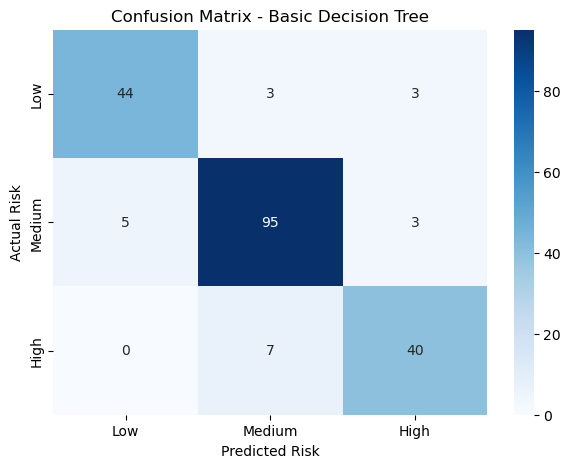

In [41]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.title("Confusion Matrix - Basic Decision Tree")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")

plt.show()

### Explanation

The confusion matrix is a 3 × 3 matrix because there are three classes.

- Rows = actual risk
- Columns = predicted risk

The diagonal values are correct predictions.

For example, the actual confusion matrix shows:

- **44 Low-risk items** correctly predicted as Low
- **95 Medium-risk items** correctly predicted as Medium
- **40 High-risk items** correctly predicted as High

The off-diagonal values are the cases where the model confused one risk class with another.


##  Overfitting Check

In [42]:
train_accuracy = decision_tree.score(X_train, y_train)
test_accuracy = decision_tree.score(X_test, y_test)

print("Training Accuracy:", round(train_accuracy, 4))
print("Testing Accuracy:", round(test_accuracy, 4))
print("Difference:", round(train_accuracy - test_accuracy, 4))

Training Accuracy: 0.9738
Testing Accuracy: 0.895
Difference: 0.0787


### Observation

The basic Decision Tree has approximately:

- Training accuracy = **97.38%**
- Testing accuracy = **89.50%**

There is a noticeable gap, which suggests some overfitting.

Decision Trees can keep creating branches to fit training observations very closely. This can reduce performance on unseen data.


##  Decision Tree Visualization

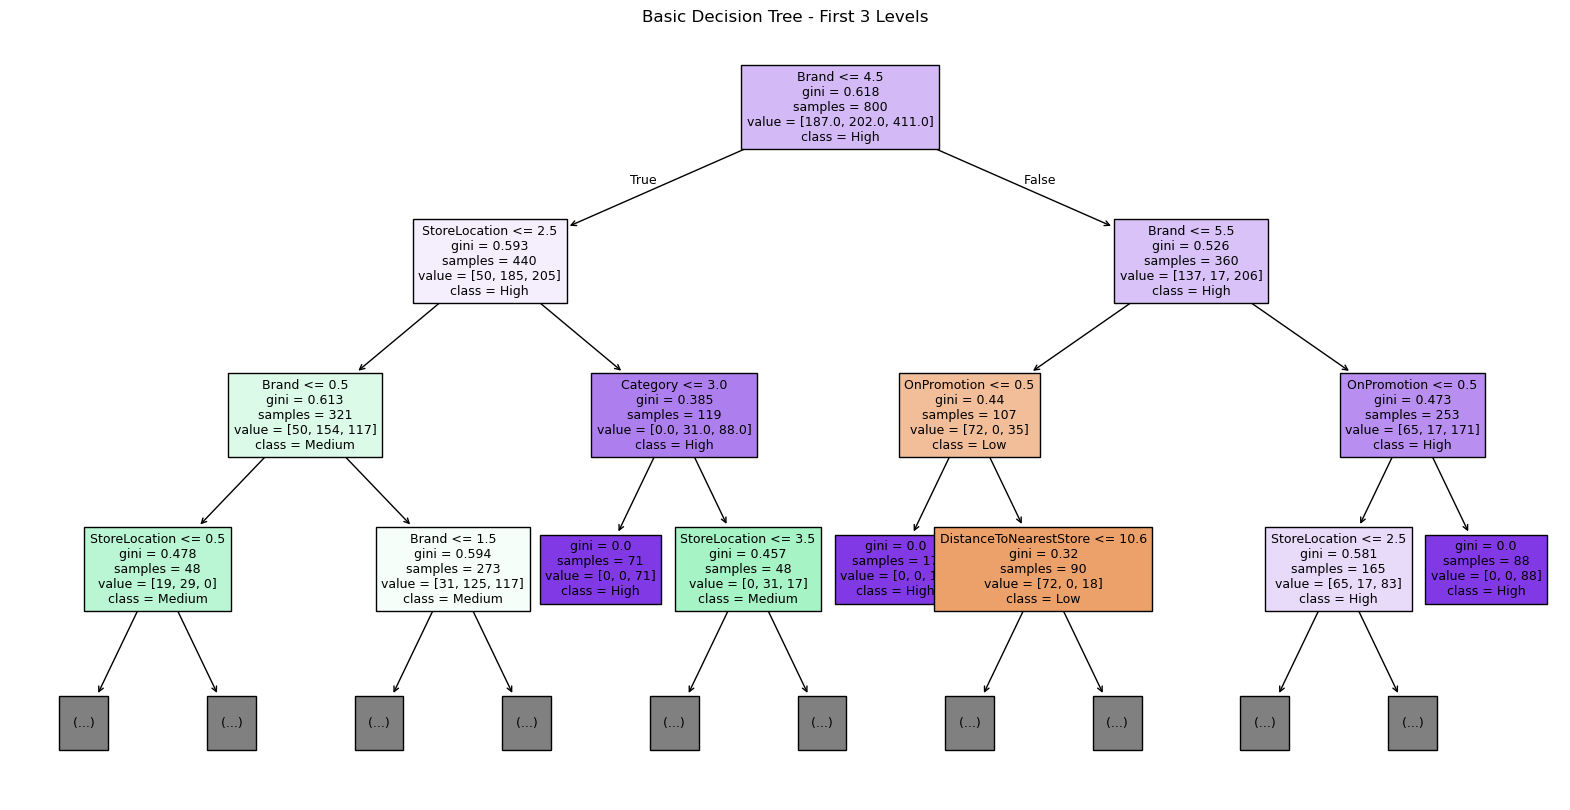

In [43]:
plt.figure(figsize=(20, 10))

plot_tree(
    decision_tree,
    feature_names=X.columns,
    class_names=["Low", "Medium", "High"],
    filled=True,
    max_depth=3,
    fontsize=9
)

plt.title("Basic Decision Tree - First 3 Levels")
plt.show()

### Explanation

The complete basic tree can become very large, so only the first three levels are displayed for readability.

The tree shows which features are used to split observations into different risk classes.

The important decision rules should be read from the actual tree shown above rather than assumed beforehand.

## Hyperparameter Tuning

### What is a hyperparameter?

A hyperparameter is a setting chosen before the model learns from the data.

For a Decision Tree:

- `max_depth` controls the maximum depth of the tree.
- `min_samples_split` controls the minimum number of samples needed to split a node.
- `min_samples_leaf` controls the minimum number of samples that should remain in a leaf.

### Why tune them?

Tuning can help control an overly complex tree and improve performance on unseen data.

### What does GridSearchCV do?

GridSearchCV tries different combinations of the selected hyperparameters using cross-validation and finds the combination with the best average validation performance.

In [44]:
param_grid = {
    "max_depth": [3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

print("Best Parameters:")
print(grid.best_params_)

Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10}


In [45]:
print("Best Estimator:")
print(grid.best_estimator_)

Best Estimator:
DecisionTreeClassifier(max_depth=10, min_samples_leaf=4, min_samples_split=10,
                       random_state=42)


In [46]:
print("Best Cross-Validation Accuracy:",
      round(grid.best_score_, 4))

Best Cross-Validation Accuracy: 0.8275


### Actual tuning result

The best parameter combination found on the actual training data is:

- `max_depth = 10`
- `min_samples_split = 10`
- `min_samples_leaf = 4`

The best 5-fold cross-validation accuracy is approximately **82.75%**.

The tuned model is selected using cross-validation rather than choosing parameters randomly.

##  Final Decision Tree Model

In [47]:
final_model = grid.best_estimator_

final_model.fit(X_train, y_train)

print("Final Decision Tree model trained.")

Final Decision Tree model trained.


### Explanation

The final model is the best Decision Tree selected by GridSearchCV.

It is still a **Decision Tree Classifier**; no other machine learning algorithm is introduced.

##  Final Model Evaluation

In [48]:
final_pred = final_model.predict(X_test)

final_accuracy = accuracy_score(y_test, final_pred)

print("Final Decision Tree Accuracy:",
      round(final_accuracy, 4))

Final Decision Tree Accuracy: 0.895


In [49]:
print("Classification Report - Final Decision Tree")

print(classification_report(
    y_test,
    final_pred,
    labels=["Low", "Medium", "High"]
))

Classification Report - Final Decision Tree
              precision    recall  f1-score   support

         Low       0.87      0.94      0.90        50
      Medium       0.92      0.89      0.91       103
        High       0.87      0.85      0.86        47

    accuracy                           0.90       200
   macro avg       0.89      0.89      0.89       200
weighted avg       0.90      0.90      0.89       200



In [50]:
final_cm = confusion_matrix(
    y_test,
    final_pred,
    labels=["Low", "Medium", "High"]
)

print(final_cm)

[[47  2  1]
 [ 6 92  5]
 [ 1  6 40]]


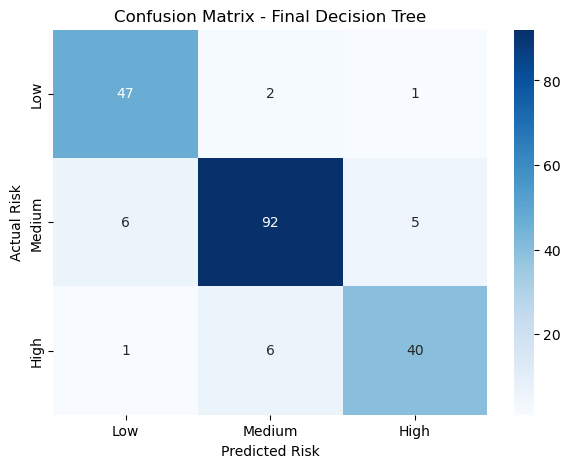

In [51]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.title("Confusion Matrix - Final Decision Tree")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")

plt.show()

In [52]:
comparison = pd.DataFrame({
    "Model": ["Basic Decision Tree", "Tuned Decision Tree"],
    "Training Accuracy": [
        decision_tree.score(X_train, y_train),
        final_model.score(X_train, y_train)
    ],
    "Testing Accuracy": [
        accuracy_score(y_test, y_pred),
        final_accuracy
    ]
})

comparison.round(4)

,Model,Training Accuracy,Testing Accuracy
0,Basic Decision Tree,0.9738,0.895
1,Tuned Decision Tree,0.8888,0.895


### Actual Model Comparison

Both the basic and tuned models achieve approximately **89.5% test accuracy** on this test split.

The tuned tree reduces training accuracy from about **97.38% to 88.88%**, which indicates that tuning made the tree less complex and reduced the overfitting gap.

##  Feature Importance

In [53]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance

,Feature,Importance
0,Brand,0.378751
2,StoreLocation,0.351263
3,OnPromotion,0.175415
5,DistanceToNearestStore,0.082404
1,Category,0.012167
4,TemperatureSensitive,0.000000


<Figure size 900x500 with 0 Axes>

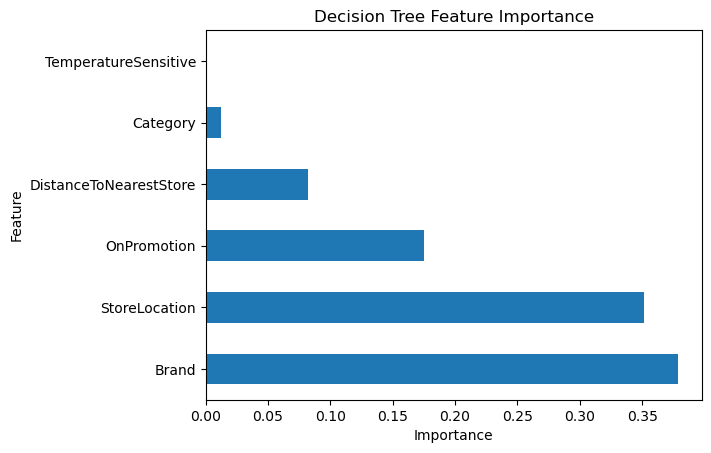

In [54]:
plt.figure(figsize=(9, 5))

feature_importance.plot(kind="barh", x="Feature", y="Importance", legend=False)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

### Actual Result

For the final tuned model, the largest feature importance values are:

- **Brand:** about 0.379
- **StoreLocation:** about 0.351
- **OnPromotion:** about 0.175
- **DistanceToNearestStore:** about 0.082
- **Category:** about 0.012
- **TemperatureSensitive:** 0.000

This means Brand and StoreLocation were the strongest contributors to the final Decision Tree's predictions.

Feature importance shows how useful a feature was to the tree; it does not prove that the feature causes obsolescence.


##  Business Insights

### Insights from the actual dataset

1. **Remaining shelf life is strongly associated with risk.**  
   High-risk items have an average of only **0.50 days** remaining, compared with **4.42 days** for Low-risk items.

2. **High-risk items have larger stock levels.**  
   Average stock quantity is **224.72** for High-risk items compared with **125.24** for Low-risk items.

3. **Slow sales are associated with higher risk.**  
   High-risk items have average daily sales of **6.72**, while Low-risk items have **15.98**.

4. **Stock coverage shows a major difference.**  
   High-risk items have average stock coverage of **72.46 days**, compared with **7.71 days** for Low-risk items.

5. **Produce has the highest High-risk share.**  
   In this dataset, **67.7%** of Produce items are classified as High risk.

6. **Delhi has the highest High-risk share among locations.**  
   Delhi has **52.8%** High-risk items.

7. **Temperature-sensitive items show higher High-risk representation.**  
   **36.4%** of temperature-sensitive items are High risk compared with **9.7%** of non-temperature-sensitive items.

8. **Distance does not show a strong group difference in the EDA.**  
   Average distance is around 8 units for all three risk groups.

### Possible business actions

Based on these patterns, a retailer could:

- monitor items with very short remaining shelf life
- avoid excessive stock for slow-moving products
- use promotions or redistribution earlier for risky inventory
- pay extra attention to high-risk categories such as Produce
- monitor stores with a larger concentration of High-risk inventory
- give special attention to temperature-sensitive products

These actions are recommendations based on patterns in this dataset, not proof of cause and effect.